# 02 · Rebuilding the order book, and proving the audit can fail

**Question:** if we replay every add / execute / cancel / delete / replace message from the start of the day, does the book stay consistent?

ITCH carries *order-level* data: each displayed order has a reference number, and later messages (execute, cancel, delete, replace) refer to it without repeating the symbol or price. To know what an execute message does you need the add that created the order. Because the sample starts at the beginning of the day, the book starts empty and every reference must resolve.

In [1]:
import time, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itch_forensics.framing import index_messages
from itch_forensics.decode import decode_all
from itch_forensics.book import build_events, replay
from itch_forensics.checks import top_of_book_state, header_frame

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
buf = pathlib.Path("../data/itch.bin").read_bytes()
idx = index_messages(buf); frames = decode_all(buf, idx)
events = build_events(frames)
KIND = {0: "add (A/F)", 1: "execute (E)", 2: "execute at price (C)", 3: "cancel (X)", 4: "delete (D)", 5: "replace (U)"}
events.kind.map(KIND).value_counts().rename("events").to_frame()

,events
kind,
add (A/F),3932096
delete (D),2362895
replace (U),532923
cancel (X),519657
execute (E),48147
execute at price (C),1344


## Replay

Python dictionaries: one entry per live order, one per price level. For the 25 symbols with the most order events, the replay also tracks the best bid and offer and records every change (this is the sample used for the top-of-book analysis below).

In [2]:
symbols = frames["R"].set_index("locate")["stock"].astype(str)
busiest = events.groupby("locate").size().nlargest(25).index.tolist()
print("monitored:", ", ".join(symbols[busiest][:12]), "...")

t = time.time()
anomalies, examples, bbo, state = replay(events, busiest)
dt = time.time() - t
print(f"{len(events):,} events replayed in {dt:.1f} s  ({len(events) / dt:,.0f} events/s, pure Python)")
print("inconsistencies found:", anomalies or "none")

monitored: UN, RIO, QQQ, TQQQ, DEO, BUD, NVS, SAP, PHG, AZN, PUK, MT ...


7,397,062 events replayed in 25.6 s  (289,135 events/s, pure Python)
inconsistencies found: none


In [3]:
pd.Series({
    "orders live at end of sample": state["live_orders"],
    "price levels at end": state["levels"],
    "resting shares, summed over orders": state["resting_shares_orders"],
    "resting shares, summed over price levels": state["resting_shares_levels"],
}).map("{:,}".format).to_frame("value")

,value
orders live at end of sample,"1,538,626"
price levels at end,"668,556"
"resting shares, summed over orders","879,432,660"
"resting shares, summed over price levels","879,432,660"


No unknown references, no duplicates, no executions or cancels larger than the remaining size, no mismatched stock locates, and the two independent totals of resting shares (by order and by price level) agree to the share.

## A clean result only counts if the audit can fail

The same replay, on the same data with one thing deliberately broken each time:

In [4]:
def replay_after(mutate):
    ev = events.copy()
    ev = mutate(ev)
    return replay(ev, [])[0]

first_delete = events[events.kind == 4].iloc[0]
def drop_the_add(ev):                  # remove the add that a later delete refers to
    return ev[~((ev.kind == 0) & (ev.ref == first_delete.ref))]
def duplicate_an_add(ev):
    i = ev.index[ev.kind == 0][100]; return pd.concat([ev.loc[:i], ev.loc[[i]], ev.loc[i + 1:]], ignore_index=True)
def oversize_a_cancel(ev):
    ev = ev.copy(); i = ev.index[ev.kind == 3][100]; ev.loc[i, "shares"] = 10**9; return ev
def wrong_locate(ev):
    ev = ev.copy(); i = ev.index[ev.kind == 4][100]; ev.loc[i, "locate"] += 1; return ev

pd.DataFrame({name: replay_after(f) for name, f in {
    "drop one add": drop_the_add, "duplicate one add": duplicate_an_add,
    "oversize one cancel": oversize_a_cancel, "wrong locate on one delete": wrong_locate}.items()}).fillna(0).astype(int).T

,delete_unknown_ref,add_duplicate_ref,cancel_over_remaining,cancel_unknown_ref,locate_mismatch
drop one add,1,0,0,0,0
duplicate one add,0,1,0,0,0
oversize one cancel,1,0,1,2,0
wrong locate on one delete,0,0,0,0,1


Each single corruption is caught and the matching counter fires. An oversized cancel also produces follow-on unknown-reference errors, because the replay removes the order and later messages about it no longer resolve. (The same four corruptions are unit tests in `tests/`, on a real one-symbol stream.)

## Top of book

Time spent in each state, averaged per symbol over the 25 busiest symbols, split at the 09:30 open. "Locked" means best bid equals best offer; "crossed" means best bid is above best offer; "one-sided" means one side has no displayed orders. "Normal" includes books whose touch is a stub quote (see below), so it says nothing about how tight the spread is.

In [5]:
end_ns = int(events.ts_ns.max())
state_time = top_of_book_state(bbo, end_ns)
(state_time / 25).round(1).rename_axis(None, axis=1).assign(**{"total (s per symbol)": lambda d: d.sum(axis=1)})

,normal,one-sided,total (s per symbol)
phase,,,
pre-market,19721.9,78.0,19799.9
regular hours,36.3,0.0,36.3


In [6]:
st = state_time.copy(); st["total"] = st.sum(axis=1)
for phase in st.index:
    print(f"{phase:>14}: normal {100 * st.loc[phase].get('normal', 0) / st.loc[phase, 'total']:5.1f}%   "
          f"locked {100 * st.loc[phase].get('locked', 0) / st.loc[phase, 'total']:5.2f}%   "
          f"crossed {100 * st.loc[phase].get('crossed', 0) / st.loc[phase, 'total']:5.2f}%   "
          f"one-sided {100 * st.loc[phase].get('one-sided', 0) / st.loc[phase, 'total']:5.1f}%")

    pre-market: normal  99.6%   locked  0.00%   crossed  0.00%   one-sided   0.4%
 regular hours: normal 100.0%   locked  0.00%   crossed  0.00%   one-sided   0.0%


## One symbol through the open

The most active monitored symbol, best bid and offer from 09:29:00 to the end of the sample. Prices are dollars.

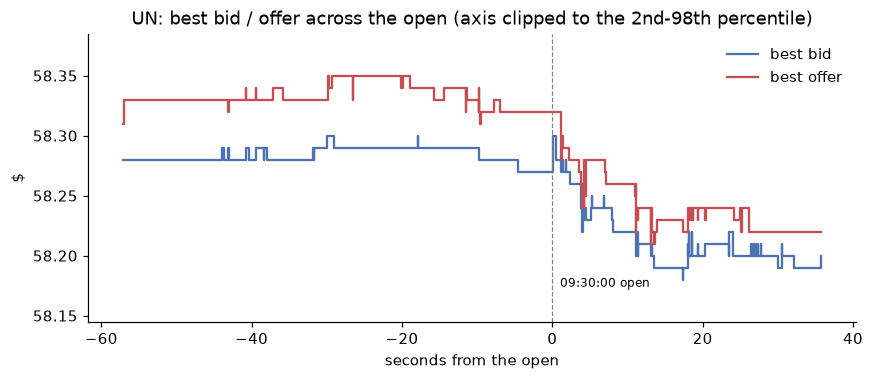

4,605 top-of-book changes for UN in the sample


In [7]:
loc = busiest[0]; name = symbols[loc]
b = bbo[bbo.locate == loc].copy()
b["t"] = b.ts_ns / 1e9 - 34200
w = b[(b.t > -60)]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.step(w.t, w.bid / 1e4, where="post", label="best bid", color="#4C72B0")
ax.step(w.t, w.ask / 1e4, where="post", label="best offer", color="#C44E52")
ax.axvline(0, color="grey", lw=0.8, ls="--"); ax.text(0.5, ax.get_ylim()[0], " 09:30:00 open", va="bottom", fontsize=8)
lo, hi = np.nanpercentile(np.r_[w.bid, w.ask] / 1e4, [2, 98]); pad = (hi - lo) * 0.3
ax.set_ylim(lo - pad, hi + pad)
ax.set_xlabel("seconds from the open"); ax.set_ylabel("$"); ax.legend(frameon=False)
ax.set_title(f"{name}: best bid / offer across the open (axis clipped to the 2nd-98th percentile)"); plt.show()
print(f"{len(b):,} top-of-book changes for {name} in the sample")

## Stub quotes

The price distribution of displayed orders has a tail at both ends. These are not errors; they are placeholder quotes a market maker leaves in the book. They matter because they make a naive average spread meaningless.

In [8]:
A = frames["A"]
hi = A[A.price >= 1_000_000_000]; lo = A[A.price <= 100]
print(f"sell orders at $100,000 or more: {len(hi):,} across {hi.stock.nunique()} symbols; "
      f"{(hi.price == 1_999_999_800).sum()} at exactly $199,999.98; buy orders in this range: {(hi.side == 'B').sum()}")
print(f"buy orders at $0.01 or less: {(lo.side == 'B').sum():,} "
      f"({(lo.price == 100).sum():,} at $0.01 and {(lo.price == 1).sum():,} at $0.0001); sell orders: {(lo.side == 'S').sum()}")

sell orders at $100,000 or more: 808 across 34 symbols; 158 at exactly $199,999.98; buy orders in this range: 0
buy orders at $0.01 or less: 4,082 (2,530 at $0.01 and 796 at $0.0001); sell orders: 50


## What this means

1. The ITCH order stream is internally consistent: every reference resolves, and the book reconciles two ways. For a market-data consumer this is the reassuring finding, and the mutation tests show it is not because the audit is blind.
2. In the 25 busiest symbols the displayed book is never locked or crossed, before or after the open; the only abnormal state is a book with one side empty, a small share of pre-market time. A single venue's feed is not the national best bid and offer, so this says nothing about locks across venues.
3. Stub quotes sit at both extremes of the price range and must be excluded before computing spreads or mid prices.

Next: [03 · Findings](03_findings.ipynb)